# SIS Analysis - Data Processing

**Objective**: Load raw environmental data (Shapefiles), clean/process it, and save to a merged Feather file for efficient analysis.

**Refactored from**: `analysis5.ipynb`

In [1]:
import sys
from pathlib import Path

# Ensure local scripts are importable
project_root = Path("../../").resolve()
sys.path.append(str(project_root))

from scripts.data_loader import load_and_process_data
from scripts.paths import ProjectPaths
import pandas as pd

print("Project Root:", project_root)

Project Root: /home/reyha/SIS_Analysis_WSL


In [2]:
# Analysis Inspection Parameters
target_season = 'Summer'
target_layer = 2

## Load and Process Data
This step checks for `data/processed/merged_gdf.feather`. If missing, it loads all raw shapefiles from `data/raw/environmental_data/`.

In [3]:
# Set force_reload=True if you added new raw data or changed the cleaning logic
merged_gdf = load_and_process_data(force_reload=True)

print("Data Shape:", merged_gdf.shape)
merged_gdf.info()

Loading raw shapefiles from 1981 to 2023...
Merging 86 shapefiles...
Processing data (cleaning DO, adding seasons)...
Saving processed data to /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Data Shape: (42326, 65)
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 42326 entries, 0 to 42325
Data columns (total 65 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   uniqueid        42326 non-null  object        
 1   zettaicode      42326 non-null  object        
 2   locationna      42326 non-null  object        
 3   wancode         42326 non-null  object        
 4   prefectuei      42326 non-null  object        
 5   watercode       42326 non-null  int64         
 6   renban          42326 non-null  object        
 7   nendo           42326 non-null  int64         
 8   survey_ym       42326 non-null  datetime64[ms]
 9   surveyyear      42326 non-null  int64         
 10  surveymont      42326

In [4]:
# Filter data for inspection using parameters
summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == target_season) & 
    (merged_gdf['saisuipoin'] == target_layer)
].dropna(subset=['do_']).copy()

# Convert do_ to numeric
summer_bottom_df['do_'] = pd.to_numeric(summer_bottom_df['do_'], errors='coerce')

# Inspect the dataset.

In [5]:
# --- STEP 1: Select Target for Inspection ---
# Assign the dataframe you want to analyze to 'df_to_inspect'
df_to_inspect = summer_bottom_df
print(f"Target DataFrame selected. Shape: {df_to_inspect.shape}")

# --- General Info ---
print("--- Data Info ---")
df_to_inspect.info()
print("\n--- First 5 Rows ---")
display(df_to_inspect.head())
print("\n--- Last 5 Rows ---")
display(df_to_inspect.tail())

Target DataFrame selected. Shape: (5362, 65)
--- Data Info ---
<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 5362 entries, 4 to 42280
Data columns (total 65 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   uniqueid        5362 non-null   object        
 1   zettaicode      5362 non-null   object        
 2   locationna      5362 non-null   object        
 3   wancode         5362 non-null   object        
 4   prefectuei      5362 non-null   object        
 5   watercode       5362 non-null   int64         
 6   renban          5362 non-null   object        
 7   nendo           5362 non-null   int64         
 8   survey_ym       5362 non-null   datetime64[ms]
 9   surveyyear      5362 non-null   int64         
 10  surveymont      5362 non-null   int64         
 11  surveyday       5362 non-null   int64         
 12  surveyhour      5362 non-null   int64         
 13  surveymini      5362 non-null   int64    

,uniqueid,zettaicode,locationna,wancode,prefectuei,watercode,renban,nendo,survey_ym,surveyyear,...,doc,doc2,dataflag,scale,geometry,year,watermass_name,division,details,season
4,0000001734,00002811,兵庫県11,03,28,301,11,1981,1981-06-01,1981,...,None,0.0,1,-1,POINT (135.33056 34.695),1981,Seto Inland Sea,Osaka Bay,North Osaka Bay,Summer
12,0000001742,00002823,兵庫県23,03,28,301,23,1981,1981-06-01,1981,...,None,0.0,1,-1,POINT (135.26389 34.65833),1981,Seto Inland Sea,Osaka Bay,North Osaka Bay,Summer
19,0000001678,00000272,大阪府2,03,27,301,2,1981,1981-06-01,1981,...,None,0.0,1,-1,POINT (135.40917 34.65833),1981,Seto Inland Sea,Osaka Bay,North Osaka Bay,Summer
27,0000001686,00000275,大阪府5,03,27,301,5,1981,1981-06-01,1981,...,None,0.0,1,-1,POINT (135.41222 34.55639),1981,Seto Inland Sea,Osaka Bay,North Osaka Bay,Summer
35,0000001694,00002725,大阪府25,03,27,301,25,1981,1981-06-01,1981,...,None,0.0,1,-1,POINT (135.26778 34.54861),1981,Seto Inland Sea,Osaka Bay,North Osaka Bay,Summer



--- Last 5 Rows ---


,uniqueid,zettaicode,locationna,wancode,prefectuei,watercode,renban,nendo,survey_ym,surveyyear,...,doc,doc2,dataflag,scale,geometry,year,watermass_name,division,details,season
42272,0000068885,00044594,大分県594,04,44,316,594,2023,2023-06-01,2023,...,None,0.0,1,-1,POINT (131.3775 33.62556),2023,Seto Inland Sea,Suo Nada,West Suō Nada,Summer
42274,0000068887,00044605,大分県605,04,44,316,605,2023,2023-06-01,2023,...,None,0.0,1,-1,POINT (131.24417 33.72556),2023,Seto Inland Sea,Suo Nada,West Suō Nada,Summer
42276,0000068889,00044677,大分県677,04,44,317,677,2023,2023-06-01,2023,...,None,0.0,1,-1,POINT (132.11083 33.28111),2023,Seto Inland Sea,Bungo Channel,Bungo Channel,Summer
42278,0000068891,00044679,大分県679,04,44,317,679,2023,2023-06-01,2023,...,None,0.0,1,-1,POINT (132.11083 33.05889),2023,Seto Inland Sea,Bungo Channel,Bungo Channel,Summer
42280,0000068893,00044690,大分県690,04,44,317,690,2023,2023-06-01,2023,...,None,0.0,1,-1,POINT (131.97556 33.28111),2023,Seto Inland Sea,Bungo Channel,Bungo Channel,Summer


In [6]:
import pandas as pd

# --- Missing Values Check ---
missing_count = df_to_inspect.isnull().sum()
missing_percent = (missing_count / len(df_to_inspect)) * 100
missing_df = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage': missing_percent
}).sort_values(by='Missing Values', ascending=False)
# Filter to show only columns with missing data
print("--- Columns with Missing Data ---")
display(missing_df[missing_df['Missing Values'] > 0])

--- Columns with Missing Data ---


,Missing Values,Percentage
rcod,5282,98.508019
doc,5159,96.214099
toc,5030,93.808280
feiochin,4095,76.370757
clearness,3631,67.717270
color,2951,55.035435
fuko,2485,46.344648
fusoku,2132,39.761283
cloud,2047,38.176054
temp,1442,26.892950


In [7]:
# --- Statistical Summary (Numeric) ---

# Ensure temperature columns are numeric so they are included in the summary
df_to_inspect['temp'] = pd.to_numeric(df_to_inspect['temp'], errors='coerce')
df_to_inspect['wtemp'] = pd.to_numeric(df_to_inspect['wtemp'], errors='coerce') # Added water temperature as well
df_to_inspect['salt'] = pd.to_numeric(df_to_inspect['salt'], errors='coerce') # Added salinity as well

print("--- Statistics for Numeric Columns ---")
display(df_to_inspect.describe().T) # Transposed for better readability

--- Statistics for Numeric Columns ---


,count,mean,min,25%,50%,75%,max,std
watercode,5362.0,310.503543,301.0,306.0,311.0,315.0,318.0,4.959309
nendo,5362.0,2002.107423,1981.0,1991.0,2002.0,2013.0,2023.0,12.431106
survey_ym,5362,2002-07-10 10:05:03.468000,1981-06-01 00:00:00,1991-06-01 00:00:00,2002-06-01 00:00:00,2013-06-01 00:00:00,2023-06-01 00:00:00,NaN
surveyyear,5362.0,2002.107423,1981.0,1991.0,2002.0,2013.0,2023.0,12.43079
surveymont,5362.0,7.05483,6.0,7.0,7.0,7.0,8.0,0.239645
surveyday,5362.0,15.619358,1.0,11.0,15.0,21.0,30.0,6.584621
surveyhour,5362.0,10.251026,0.0,9.0,10.0,12.0,18.0,2.694552
surveymini,5362.0,27.14379,0.0,10.0,27.0,43.0,59.0,17.935802
saisuipoin,5362.0,2.0,2.0,2.0,2.0,2.0,2.0,0.0
latitude,5362.0,34.026774,32.947778,33.836667,34.098333,34.330833,34.763333,0.423561


--- Spatial Distribution of Data Points ---

Map Bounds (MinX, MinY, MaxX, MaxY): [130.8058333   32.94777778 135.4122222   34.76333333]


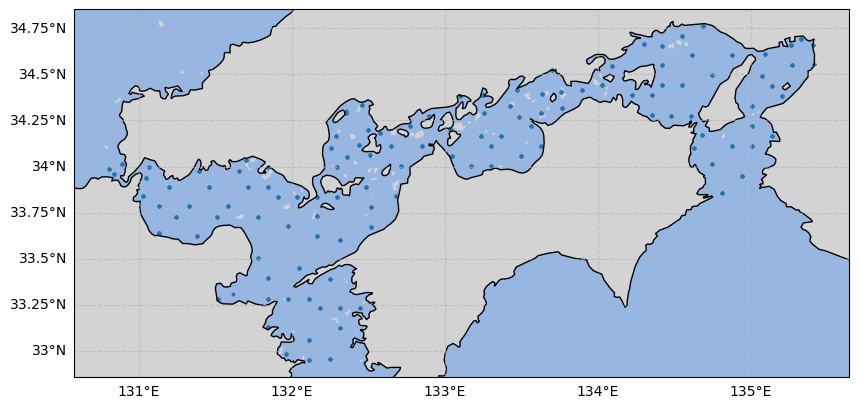

In [9]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --- Quick Spatial Plot ---
if hasattr(df_to_inspect, 'geometry'):
    print("--- Spatial Distribution of Data Points ---")
    
    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})
    
    # Add background features
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN)
    ax.add_feature(cfeature.COASTLINE)
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.6)
    gl.top_labels = False
    gl.right_labels = False
    
    # Plot spatial data
    df_to_inspect.plot(ax=ax, markersize=2, alpha=0.5, transform=ccrs.PlateCarree())
    
    # Check Bounds
    bounds = df_to_inspect.total_bounds
    print(f"\nMap Bounds (MinX, MinY, MaxX, MaxY): {bounds}")
else:
    print("DataFrame does not have a geometry column.")

In [10]:
# === Find out the depth range of both 'saisuipoin' category ===

# Convert 'depth' column to numeric, forcing non-numeric values to NaN (since it is currently Object type)
merged_gdf['depth'] = pd.to_numeric(merged_gdf['depth'], errors='coerce')

# Group by 'saisuipoin' and calculate the minimum and maximum depth
depth_ranges = merged_gdf.groupby('saisuipoin')['depth'].agg(['min', 'max'])

# Display the results
print("Depth ranges for each 'saisuipoin' category:")
print(depth_ranges)

Depth ranges for each 'saisuipoin' category:
            min    max
saisuipoin            
1           0.5  179.0
2           1.1  179.0


--- Spatial Distribution of Data Points ---



Map Bounds (MinX, MinY, MaxX, MaxY): [130.8058333   32.94777778 135.4122222   34.76333333]


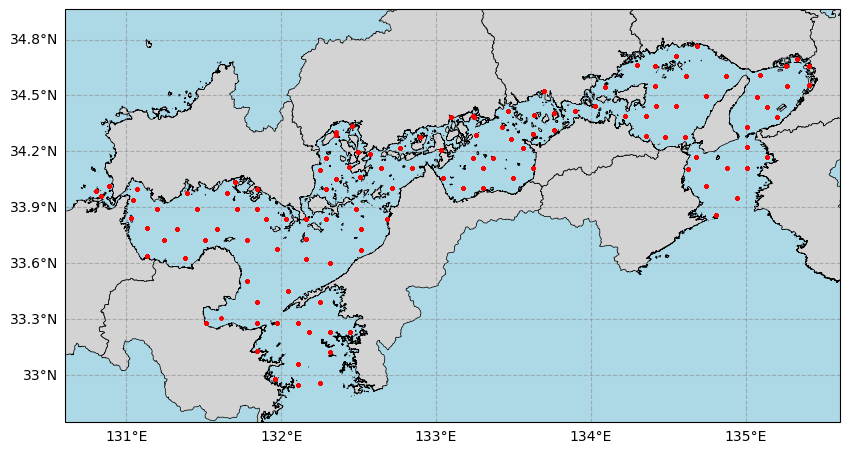

In [11]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scripts.paths import ProjectPaths

# --- Quick Spatial Plot ---
if hasattr(df_to_inspect, 'geometry'):
    print("--- Spatial Distribution of Data Points ---")
    
    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})
    
    # 1. Set the background color to a more visible blue
    # Changed from 'azure' to 'lightblue' so the sea is clearly visible
    ax.set_facecolor('lightblue')
    
    # 2. Load the Setonaikai boundary file
    boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary.shp"
    sis_boundary = gpd.read_file(boundary_path)
    
    # Ensure it's in WGS84 to match the plot projection
    if sis_boundary.crs != "EPSG:4326":
        sis_boundary = sis_boundary.to_crs("EPSG:4326")
    
    # 3. Plot the detailed SIS boundary as the land/coastline context
    # This overlays the land (lightgray) on top of the lightblue background
    sis_boundary.plot(ax=ax, facecolor='lightgray', edgecolor='black', linewidth=0.5, transform=ccrs.PlateCarree(), zorder=1)
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5, zorder=2)
    gl.top_labels = False
    gl.right_labels = False
    
    # Plot spatial data (survey points)
    df_to_inspect.plot(ax=ax, markersize=3, color='red', alpha=0.8, transform=ccrs.PlateCarree(), zorder=3)
    
    # Optional: Set the extent to tightly fit the data with a small buffer
    bounds = df_to_inspect.total_bounds
    ax.set_extent([bounds[0]-0.2, bounds[2]+0.2, bounds[1]-0.2, bounds[3]+0.2], crs=ccrs.PlateCarree())
    
    print(f"\nMap Bounds (MinX, MinY, MaxX, MaxY): {bounds}")
else:
    print("DataFrame does not have a geometry column.")